# What the screen's own controls say

Four results that bound every candidate this screen has produced. Each panel is a control
that could have come out the other way.

- **a** the construct bug: pairs whose interface was carried by a prohormone the cell never releases
- **b** the known-answer matrix: textbook receptor-ligand pairs run through the screen's own pipeline
- **c** whether the *pairing* carries signal once each receptor's and each peptide's own tendency is removed
- **d** an external baseline, RF2-PPI's deposited DCA score, against our statistic

In [1]:
import json
import pathlib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy import stats

ROOT = pathlib.Path('/data/yzy21/yy/space_agent/structural_modelling')
RES = ROOT / 'results'
GATE = json.loads((RES / 'protein_thresholds.json').read_text())['gate']['pae_min_AB_max']
GATE

3.76

In [2]:
RED, BLUE, GREY, INK = '#B2182B', '#2166AC', '#9A9AA2', '#1A1A1F'
mpl.rcParams.update({
    'figure.dpi': 140, 'savefig.dpi': 300, 'font.size': 8.5,
    'axes.linewidth': .8, 'axes.edgecolor': INK, 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'xtick.major.width': .8, 'ytick.major.width': .8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
})

## a. The construct bug

`scripts/44` cut each secreted partner at the signal peptide and folded everything after it.
UniProt also annotates PROPEPTIDE, PEPTIDE and CHAIN, which that rule never read, so a
prohormone was folded as a prohormone. Every pair whose precursor cleared the gate was
re-folded as each product the protein is actually processed into -- same receptor, same
alignments, same seed, the span is the only difference.

In [3]:
lp = pd.read_csv(RES / 'ligand_product_scores.csv')
lp = lp[~lp['product'].str.contains('PRECURSOR')].copy()

# A span covering (almost) the whole precursor is the prohormone again, not a released
# product; so is the GnRH-associated peptide, the remnant left after the decapeptide is cut.
lp['frac'] = lp['len'] / lp['precursor_len']
released = lp[(lp.frac < 0.90) & (~lp['product'].str.contains('associated peptide'))]

best = (released.sort_values('pae_min')
        .groupby(['receptor', 'partner'], as_index=False).first())
best = best[best.pre_min.notna()]
best['pair'] = best.receptor + ' + ' + best.partner
best['lost'] = (best.pre_min <= GATE) & (best.pae_min > GATE)
best[['pair', 'product', 'len', 'precursor_len', 'pre_min', 'pae_min', 'lost']] \
    .sort_values('pae_min')

,pair,product,len,precursor_len,pre_min,pae_min,lost
11,MRGPRX2 + SPX,Spexin-1,14,90,2.59,1.54,False
7,GPRC5A + NTF4,Neurotrophin-4,130,186,3.26,2.16,False
0,GPR142 + ADCYAP1,Pituitary adenylate cyclase-activating polypep...,38,152,3.57,3.28,False
3,GPR22 + EFNA5,Ephrin-A5,183,208,3.60,3.93,True
12,MRGPRX4 + GHRL,Ghrelin-27,27,94,3.73,4.11,True
9,MRGPRX1 + GHRL,Ghrelin-27,27,94,2.69,4.18,True
10,MRGPRX2 + GNRH2,Gonadoliberin-2,10,97,2.17,6.49,True
4,GPR32 + CFC1,Cryptic protein,133,198,3.75,8.50,True
5,GPR32 + GHRL,Obestatin,23,94,3.63,8.88,True
1,GPR148 + CFC1,Cryptic protein,133,198,3.17,10.94,True


In [4]:
print(f"pairs whose PRECURSOR cleared {GATE} A : {(best.pre_min <= GATE).sum()}")
print(f"  still clear it as a released product: {(~best.lost).sum()}")
print(f"  lose the interface                  : {best.lost.sum()}")

pairs whose PRECURSOR cleared 3.76 A : 12
  still clear it as a released product: 3
  lose the interface                  : 9


## b. The known-answer matrix

The control the project defined in `scripts/39` and never ran: textbook receptor-ligand
pairs pushed through the same pipeline as the orphans -- sliced products, hhfilter-90
alignments, paired omicMSA. Every known peptide against every known receptor, so the
comparison is inside one arm and the paired-alignment depth is comparable.

In [5]:
km = pd.read_csv(RES / 'known_matrix_scores.csv')
km['short'] = km['product'].replace(
    {'Pituitary adenylate cyclase-activating polypeptide 38': 'PACAP-38'})
piv = km.pivot_table(index='short', columns='receptor', values='pae')
tru = km.pivot_table(index='short', columns='receptor', values='true').fillna(False)
order = piv.median().sort_values().index
piv, tru = piv[order], tru[order]
print(f"{len(km)} cells, {km.true.sum()} true pairs, {(~km.true).sum()} matched negatives")
print(f"true pairs clearing the gate : {(km[km.true].pae <= GATE).sum()} of {km.true.sum()}")
print(f"negatives clearing the gate  : {(km[~km.true].pae <= GATE).sum()} of {(~km.true).sum()}")

72 cells, 9 true pairs, 63 matched negatives
true pairs clearing the gate : 4 of 9
negatives clearing the gate  : 5 of 63


/tmp/ipykernel_2807227/3020082853.py:5: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  tru = km.pivot_table(index='short', columns='receptor', values='true').fillna(False)


In [6]:
ranks = []
for prod, g in km.groupby('short'):
    if not g.true.any() or len(g) < 3:      # a row with one cell cannot rank
        continue
    g = g.sort_values('pae')
    ranks.append({'peptide': prod, 'n': len(g),
                  'rank': int(np.where(g.true.values)[0][0]) + 1,
                  'norm': (int(np.where(g.true.values)[0][0]) + 1) / len(g),
                  'best_other': g[~g.true].pae.min()})
ranks = pd.DataFrame(ranks)
w = stats.wilcoxon(ranks.norm - 0.5, alternative='less')
print(ranks.to_string(index=False))
print(f"\ntrue receptor ranks first: {(ranks['rank'] == 1).sum()} of {len(ranks)}")
print(f"normalised rank median {ranks.norm.median():.3f} vs 0.5 expected, "
      f"one-sided Wilcoxon p = {w.pvalue:.4f}")

       peptide  n  rank     norm  best_other
    Ghrelin-28 14    10 0.714286        2.20
  Neuromedin-S 14     1 0.071429        5.95
Neurotrophin-4 14     2 0.142857        2.19
      PACAP-38 15     1 0.066667        3.39
      Spexin-1 14     2 0.142857        1.57

true receptor ranks first: 2 of 5
normalised rank median 0.143 vs 0.5 expected, one-sided Wilcoxon p = 0.0625


## c. Is it the pairing, or just which receptor and which peptide?

A receptor that docks anything well, or a peptide that docks nowhere, hands a true pair a
low PAE without the pairing mattering. Median polish removes an additive receptor effect and
an additive peptide effect; what is left is the pairing. The decomposition is not unique, so
both sweep orders are reported.

In [7]:
def polish(M, first='row', it=12):
    R = M - np.nanmedian(M)
    for _ in range(it):
        steps = ['row', 'col'] if first == 'row' else ['col', 'row']
        for s in steps:
            if s == 'row':
                R -= np.nan_to_num(np.nanmedian(R, axis=1))[:, None]
            else:
                R -= np.nan_to_num(np.nanmedian(R, axis=0))[None, :]
    return R

resid = {}
for first in ('row', 'col'):
    R = pd.DataFrame(polish(piv.values.astype(float), first),
                     index=piv.index, columns=piv.columns)
    t = [R.loc[q.short, q.receptor] for q in km.itertuples() if q.true]
    n = [R.loc[q.short, q.receptor] for q in km.itertuples() if not q.true]
    t, n = [v for v in t if pd.notna(v)], [v for v in n if pd.notna(v)]
    p = stats.mannwhitneyu(t, n, alternative='less').pvalue
    resid[first] = (t, n, p)
    print(f"{first}-first: true median {np.median(t):+.2f} A, "
          f"negatives {np.median(n):+.2f} A, Mann-Whitney p = {p:.4f}")

row-first: true median -0.64 A, negatives +0.00 A, Mann-Whitney p = 0.0157
col-first: true median -0.41 A, negatives +0.00 A, Mann-Whitney p = 0.0112


## d. An external baseline

RF2-PPI deposited a DCA score for 189M human pairs and an AlphaFold2 score for 3.38M. If
their statistic and ours ranked the same pairs, the screen would be re-deriving a published
result; if they are uncorrelated, the two are looking at different things and neither
corroborates the other.

In [8]:
rf = pd.read_csv(RES / 'rf2ppi_comparison.csv')
rf = rf[rf.dca.notna() & rf.pae_min_AB.notna()]
rho, prho = stats.spearmanr(rf.dca, rf.pae_min_AB)
hit = rf[rf.pae_min_AB <= GATE]
print(f"{len(rf)} pairs carry a deposited DCA score")
print(f"Spearman rho(DCA, interface PAE) = {rho:+.3f}  (p = {prho:.4f})")
print(f"gate hits median DCA {hit.dca.median():.3f} vs rest {rf[rf.pae_min_AB > GATE].dca.median():.3f}, "
      f"Mann-Whitney p = {stats.mannwhitneyu(hit.dca, rf[rf.pae_min_AB > GATE].dca).pvalue:.3f}")

1590 pairs carry a deposited DCA score
Spearman rho(DCA, interface PAE) = -0.063  (p = 0.0116)
gate hits median DCA 0.082 vs rest 0.075, Mann-Whitney p = 0.786


## The figure

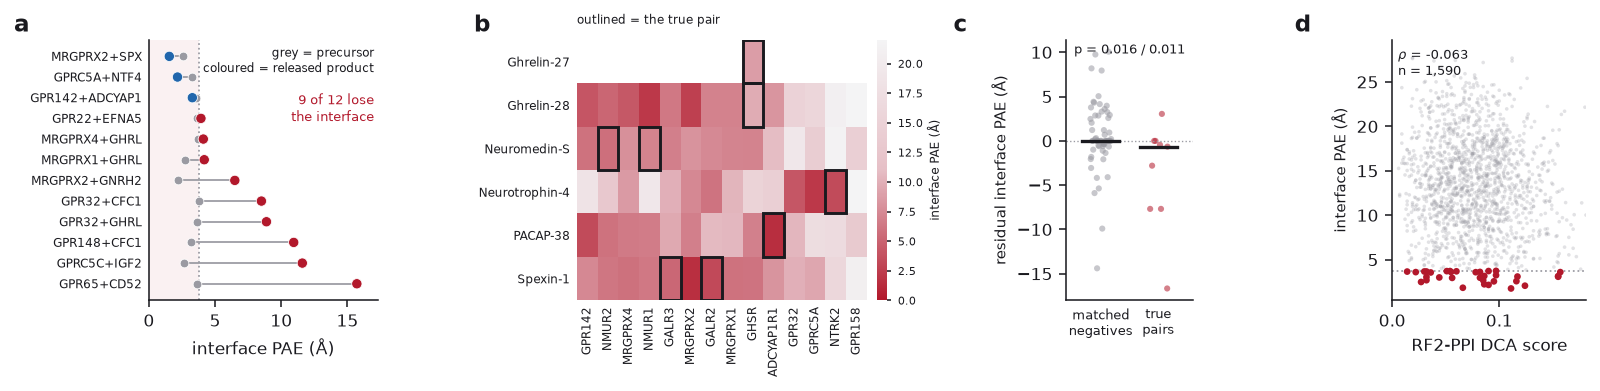

In [9]:
fig = plt.figure(figsize=(11.8, 3.05))
gs = fig.add_gridspec(1, 4, width_ratios=[1.12, 1.42, .62, .95], wspace=.95,
                      left=.115, right=.985, bottom=.235, top=.845)
LETTER = dict(fontsize=12, fontweight='bold', va='top', ha='right')

# ---- a. precursor vs released product, paired ------------------------------
ax = fig.add_subplot(gs[0, 0])
b = best.sort_values('pae_min', ascending=False).reset_index(drop=True)
y = np.arange(len(b))
ax.axvspan(0, GATE, color=RED, alpha=.06, lw=0)
ax.axvline(GATE, color=GREY, lw=.9, ls=':')
for i, q in b.iterrows():
    ax.plot([q.pre_min, q.pae_min], [i, i], color=GREY, lw=.9, zorder=1)
ax.scatter(b.pre_min, y, s=20, color=GREY, zorder=3, edgecolor='white', linewidth=.4)
ax.scatter(b.pae_min, y, s=28, zorder=4, edgecolor='white', linewidth=.4,
           color=[RED if l else BLUE for l in b.lost])
ax.set_yticks(y)
ax.set_yticklabels([f'{q.receptor}+{q.partner}' for _, q in b.iterrows()], fontsize=6.1)
ax.set_xlabel('interface PAE (Å)')
ax.set_xlim(0, b.pae_min.max() * 1.1)
ax.set_ylim(-.8, len(b) - .2)
ax.tick_params(axis='y', length=0)
ax.text(.985, .975, 'grey = precursor\ncoloured = released product',
        transform=ax.transAxes, ha='right', va='top', fontsize=6.2, color=INK)
ax.text(.985, .80, f'{int(b.lost.sum())} of {int((b.pre_min <= GATE).sum())} lose\nthe interface',
        transform=ax.transAxes, ha='right', va='top', fontsize=6.8, color=RED)
ax.text(-.52, 1.10, 'a', transform=ax.transAxes, **LETTER)

# ---- b. the known-answer matrix -------------------------------------------
ax = fig.add_subplot(gs[0, 1])
cmap = LinearSegmentedColormap.from_list('pae', [RED, '#E6BFC6', '#F4F4F5'])
im = ax.imshow(piv.values, cmap=cmap, vmin=0, vmax=22, aspect='auto')
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        if np.isnan(piv.values[i, j]):
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor='white',
                                   edgecolor='none', zorder=2))
        if tru.values[i, j]:
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False,
                                   edgecolor=INK, lw=1.5, zorder=4))
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=90, fontsize=6)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=6.4)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cax = ax.inset_axes([1.035, 0, .035, 1])
cb = fig.colorbar(im, cax=cax)
cb.ax.tick_params(labelsize=5.8, length=2)
cb.outline.set_visible(False)
cb.set_label('interface PAE (Å)', fontsize=6, labelpad=2)
ax.text(.0, 1.10, 'outlined = the true pair', transform=ax.transAxes, fontsize=6.4,
        va='top', color=INK)
ax.text(-.30, 1.10, 'b', transform=ax.transAxes, **LETTER)

# ---- c. residual after removing receptor and peptide effects ---------------
ax = fig.add_subplot(gs[0, 2])
t, n, p_row = resid['row']
rng = np.random.default_rng(0)
for x, v, c in ((0, n, GREY), (1, t, RED)):
    ax.scatter(x + rng.uniform(-.18, .18, len(v)), v, s=10, color=c, alpha=.55,
               edgecolor='none')
    ax.plot([x - .32, x + .32], [np.median(v)] * 2, color=INK, lw=1.7, zorder=5)
ax.axhline(0, color=GREY, lw=.7, ls=':')
ax.set_xticks([0, 1])
ax.set_xticklabels(['matched\nnegatives', 'true\npairs'], fontsize=6.6)
ax.set_xlim(-.6, 1.6)
ax.tick_params(axis='x', length=0)
ax.set_ylabel('residual interface PAE (Å)', fontsize=7.5)
ax.text(.5, .985, f"p = {p_row:.3f} / {resid['col'][2]:.3f}", transform=ax.transAxes,
        ha='center', va='top', fontsize=6.6, color=INK)
ax.text(-.78, 1.10, 'c', transform=ax.transAxes, **LETTER)

# ---- d. RF2-PPI DCA against our statistic ---------------------------------
ax = fig.add_subplot(gs[0, 3])
ax.scatter(rf.dca, rf.pae_min_AB, s=3.5, color=GREY, alpha=.28, edgecolor='none')
ax.scatter(hit.dca, hit.pae_min_AB, s=12, color=RED, edgecolor='none', zorder=3)
ax.axhline(GATE, color=GREY, lw=.9, ls=':')
ax.set_xlabel('RF2-PPI DCA score'); ax.set_ylabel('interface PAE (Å)', fontsize=7.5)
ax.set_xlim(0, np.percentile(rf.dca, 99.5))
ax.text(.03, .97, f'$\\rho$ = {rho:+.3f}\nn = {len(rf):,}', transform=ax.transAxes,
        ha='left', va='top', fontsize=6.8)
ax.text(-.42, 1.10, 'd', transform=ax.transAxes, **LETTER)

fig.savefig('screen_controls.png', bbox_inches='tight', facecolor='white')
fig.savefig('screen_controls.pdf', bbox_inches='tight', facecolor='white')
plt.show()